# Second Practice
### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336
##### We have been able to cooperate during the whole practice, very little individual work

In [21]:
# Necessary libraries
import numpy as np
import matplotlib.pyplot as plt

## 1. Gradient descent methods

### 1.1 A simple quadratic function

We will define $f$ as:
$$
    f(x)=x_{1}^{2} + x_{2}^{2}
$$

By derivating, we obtain the gradient:
$$
    \nabla f(x) = (2x_{1}, 2x_{2})
$$

Now we perform the next experiments

#### 1.1.1 Implement gradient descent with a constant $\alpha^{k} = 0.1$.

In [22]:
def grad_desc(f, grad_f, x0, alpha, max_iter):
    x=x0
    counter = 0
    for i in range(max_iter):
        counter += 1
        x = x -alpha * grad_f(x)
    return x, f(x)

def f(x): return x[0]**2 + x[1]**2
def grad_f(x): return np.array([2*x[0], 2*x[1]])

In [23]:
x0 = np.random.uniform(-200, 200, 2)

x_final, f_final = grad_desc(f, grad_f, x0, alpha=0.1, max_iter=100)

print(f"Initial point: x0   = [{x0[0]:.4f}, {x0[1]:.4f}]")
print(f"Final point:   x    = [{x_final[0]:.2e}, {x_final[1]:.2e}]")
print(f"Final value:   f(x) = {f_final:.2e}")


Initial point: x0   = [61.3821, -1.5415]
Final point:   x    = [1.25e-08, -3.14e-10]
Final value:   f(x) = 1.56e-16


We see that the gradient descent converges to the point $(0,0)$ where $f$ has a minimum. The minimum is at that point as the solution to the equation $\nabla f(x)= 0$, in other words, $(2x_{1}, 2x_{2}) = 0$ is found at $(0,0)$.

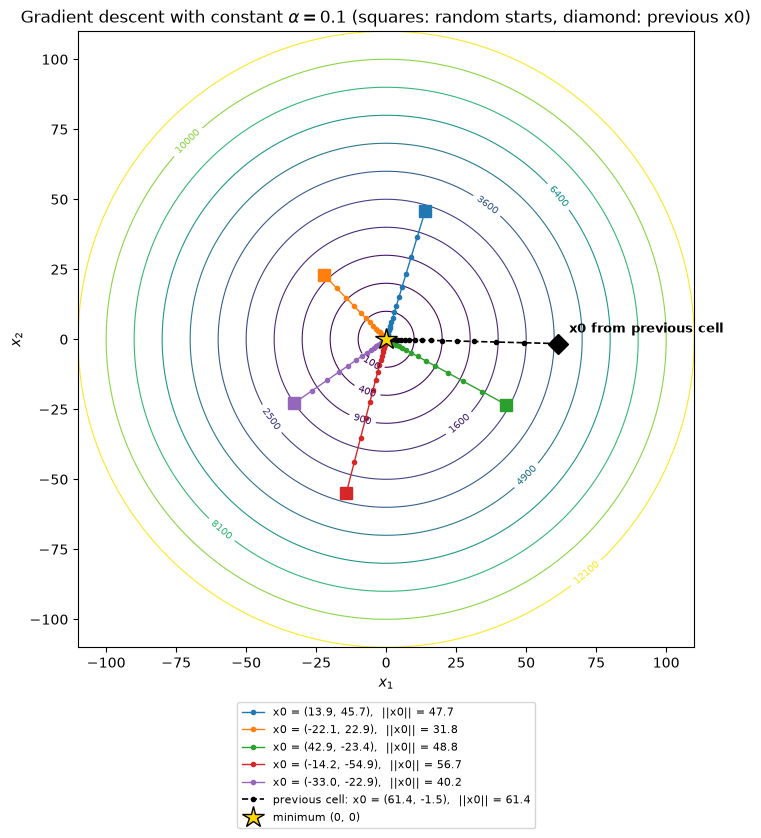

In [24]:
# MADE WITH AI

def grad_desc_path(grad_f, x0, alpha, max_iter):
    # Same iteration as grad_desc, but keeps every point to draw the trajectory
    x = x0
    path = [x]
    for i in range(max_iter):
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

# 5 random starting points at a distance between 30 and 100 from (0, 0)
r = np.random.uniform(30, 100, 5)
theta = np.random.uniform(0, 2*np.pi, 5)
starts = np.column_stack([r*np.cos(theta), r*np.sin(theta)])

# The x0 from the previous cell can be further away, so the plot limits adapt to it
lim = 1.1 * max(100, np.linalg.norm(x0))
step = 10 if lim <= 120 else 25

# Contour lines of f (circles of radius step, 2*step, ...)
X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
Z = f(np.array([X, Y]))

fig, ax = plt.subplots(figsize=(8, 8))
cs = ax.contour(X, Y, Z, levels=[k**2 for k in np.arange(step, lim, step)], cmap="viridis", linewidths=0.8)
ax.clabel(cs, fontsize=7, fmt="%.0f")

colors = plt.cm.tab10.colors
for i, start in enumerate(starts):
    path = grad_desc_path(grad_f, start, alpha=0.1, max_iter=100)
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
    ax.plot(*start, "s", color=colors[i], ms=9)

# x0 from the previous cell, drawn in black with a dashed line and a diamond
path = grad_desc_path(grad_f, x0, alpha=0.1, max_iter=100)
ax.plot(path[:, 0], path[:, 1], "--o", color="k", ms=3, lw=1.2,
        label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
ax.plot(*x0, "D", color="k", ms=10)
ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

ax.plot(0, 0, "*", color="gold", mec="k", ms=16, label="minimum (0, 0)")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$ (squares: random starts, diamond: previous x0)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.show()

#### 1.1.2 Try gain with $\alpha^{k} = 1$ and $\alpha^{k} = 2$

In [36]:
print(f"Initial point: x0   = [{x0[0]:.4f}, {x0[1]:.4f}]")

x_final_1, f_final_1 = grad_desc(f, grad_f, x0, alpha=1, max_iter=100)

print("\n\nalpha = 1")
print(f"Final point:   x    = [{x_final_1[0]:.4f}, {x_final_1[1]:.4f}]")
print(f"Final value:   f(x) = {f_final_1:.4f}")

x_final_2, f_final_2 = grad_desc(f, grad_f, x0, alpha=2, max_iter=100)

print("\n\nalpha = 2")
print(f"Final point:   x    = [{x_final_2[0]:.2e}, {x_final_2[1]:.2e}]")
print(f"Final value:   f(x) = {f_final_2:.2e}")

Initial point: x0   = [61.3821, -1.5415]


alpha = 1
Final point:   x    = [61.3821, -1.5415]
Final value:   f(x) = 3770.1400


alpha = 2
Final point:   x    = [3.16e+49, -7.94e+47]
Final value:   f(x) = 1.00e+99


In [ ]:
# MADE WITH AI

# Distance from (0, 0) of every iterate, starting from the same x0 as in 1.1.1
path_1 = grad_desc_path(grad_f, x0, alpha=1, max_iter=100)
path_2 = grad_desc_path(grad_f, x0, alpha=2, max_iter=100)
dist_1 = np.linalg.norm(path_1, axis=1)
dist_2 = np.linalg.norm(path_2, axis=1)

print(f"{'k':>3} | {'x_k (alpha = 1)':>22} | {'||x_k|| (alpha = 1)':>20} | {'x_k (alpha = 2)':>26} | {'||x_k|| (alpha = 2)':>20}")
print("-" * 103)
for k, (p1, d1, p2, d2) in enumerate(zip(path_1, dist_1, path_2, dist_2)):
    point_1 = f"({p1[0]:.4f}, {p1[1]:.4f})"
    point_2 = f"({p2[0]:.4e}, {p2[1]:.4e})"
    print(f"{k:>3} | {point_1:>22} | {d1:>20.4f} | {point_2:>26} | {d2:>20.4e}")

Since $\nabla f(x) = 2x$, one step of gradient descent with constant $\alpha$ is
$$
    x^{k+1} = x^{k} - 2\alpha x^{k} = (1 - 2\alpha)\, x^{k}
    \quad\Longrightarrow\quad
    x^{k} = (1 - 2\alpha)^{k} x^{0}, \qquad \|x^{k}\| = |1 - 2\alpha|^{k}\, \|x^{0}\|
$$

- **$\alpha = 1$:** the factor is $1 - 2 = -1$, so $x^{k+1} = -x^{k}$. The iterates just bounce between $x^{0}$ and $-x^{0}$, and the distance to the minimum stays equal to $\|x^{0}\|$ in every iteration. The method never gets closer to $(0, 0)$.
- **$\alpha = 2$:** the factor is $1 - 4 = -3$, so the iterate changes sign and its distance to the minimum is multiplied by 3 in every iteration, the method diverges.

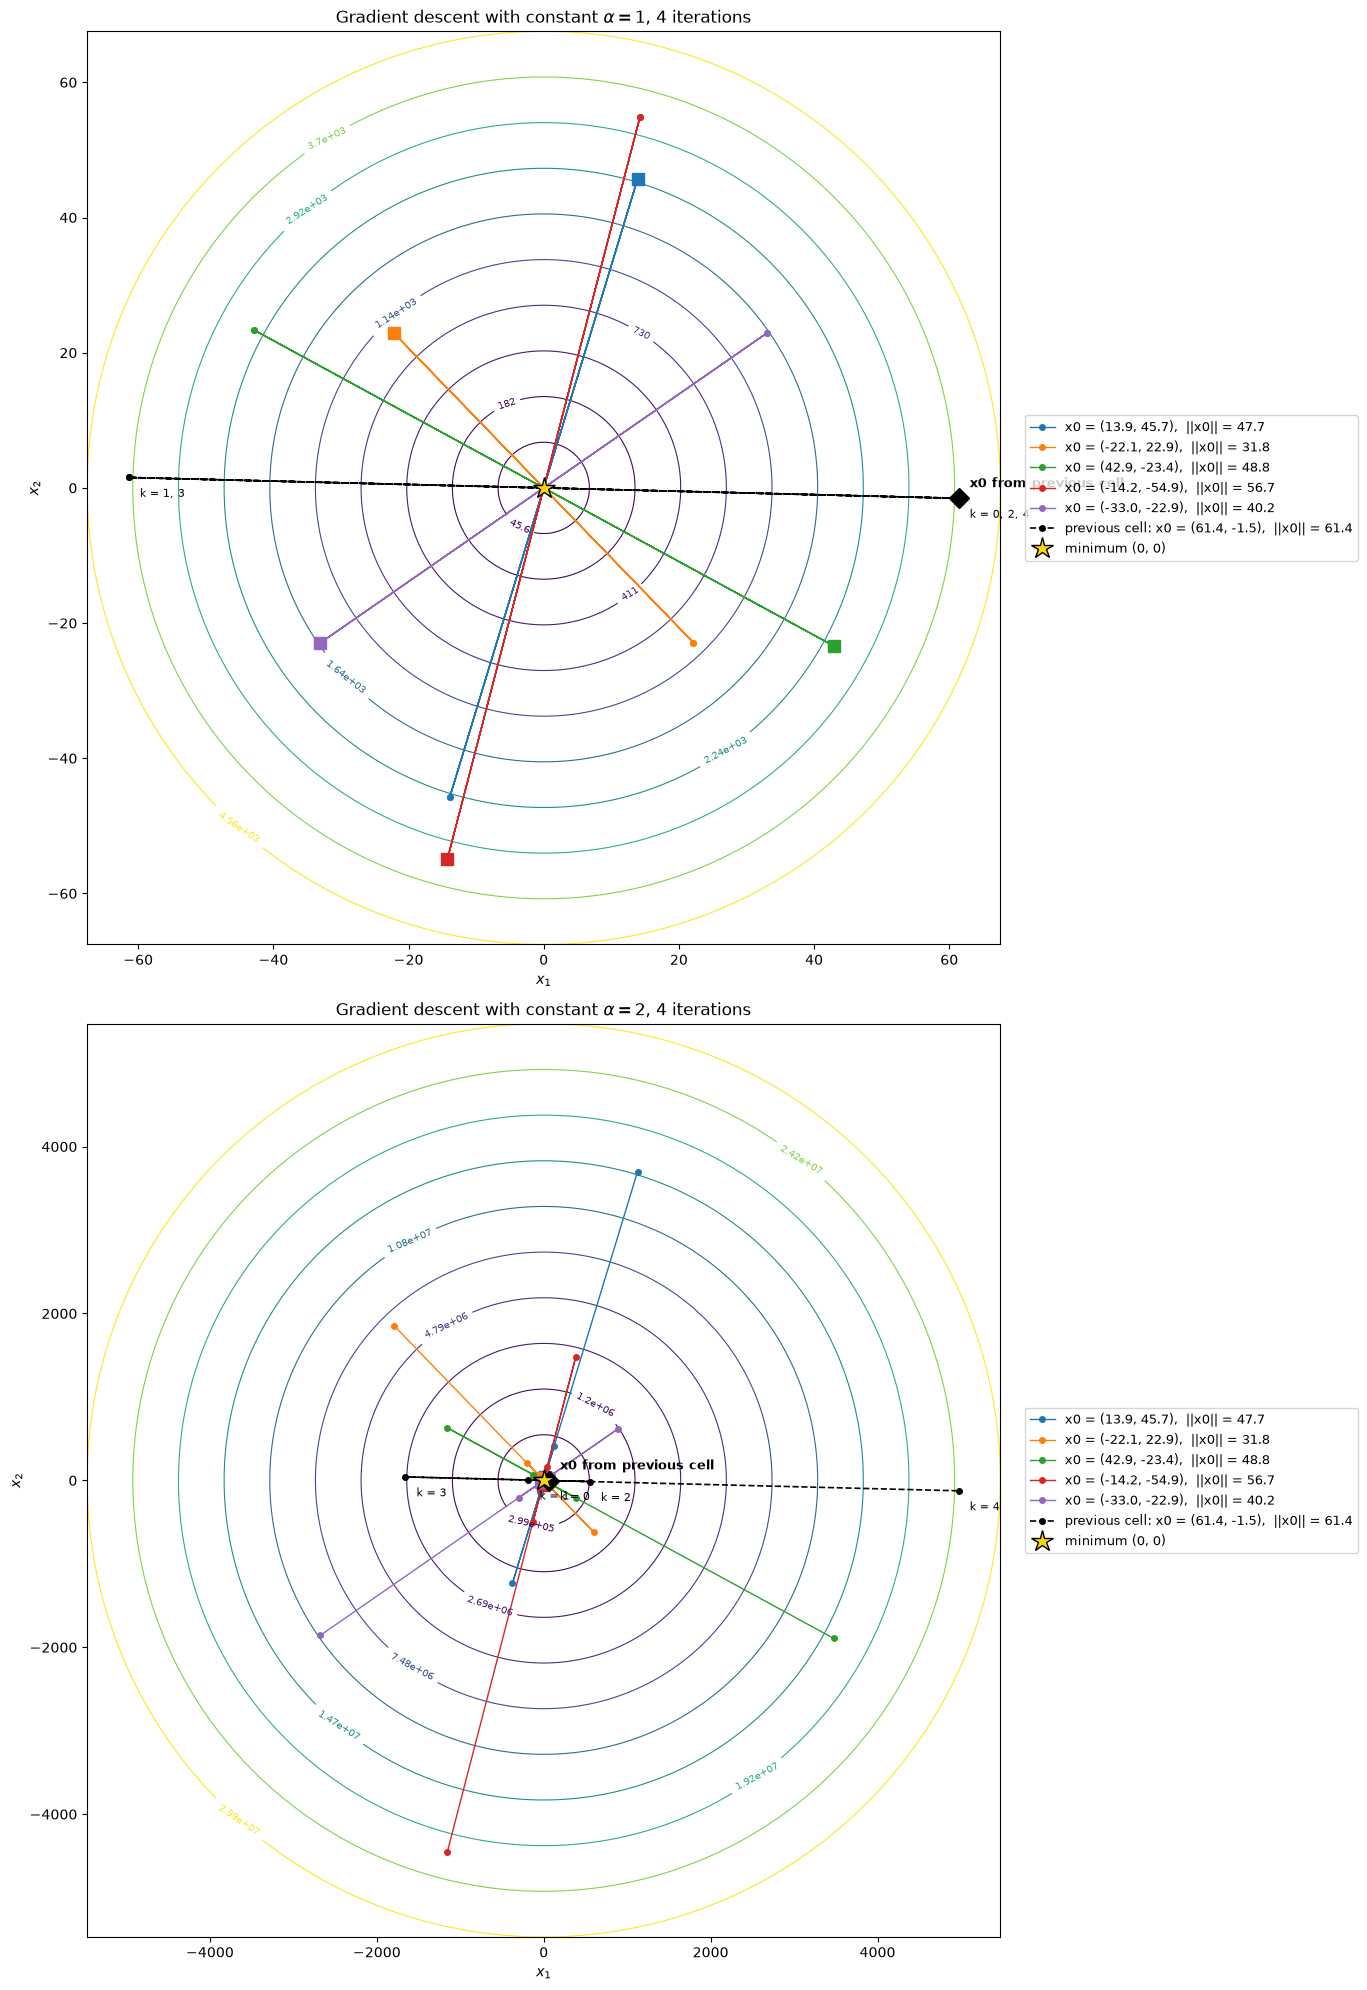

In [26]:
# MADE WITH AI

# Same plot as in 1.1.1 (same 5 random starts and x0 from cell 7), now with alpha = 1 and alpha = 2, 4 iterations
fig, axes = plt.subplots(2, 1, figsize=(12, 20))
colors = plt.cm.tab10.colors

for ax, alpha in zip(axes, [1, 2]):
    paths = [grad_desc_path(grad_f, start, alpha=alpha, max_iter=4) for start in starts]
    path_prev = grad_desc_path(grad_f, x0, alpha=alpha, max_iter=4)

    # Plot limits and contour lines adapt to how far the iterates go
    lim = 1.1 * max(np.linalg.norm(p, axis=1).max() for p in paths + [path_prev])
    X, Y = np.meshgrid(np.linspace(-lim, lim, 400), np.linspace(-lim, lim, 400))
    Z = f(np.array([X, Y]))
    cs = ax.contour(X, Y, Z, levels=np.linspace(0, lim, 11)[1:]**2, cmap="viridis", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.3g")

    for i, (start, path) in enumerate(zip(starts, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=4, lw=1,
                label=f"x0 = ({start[0]:.1f}, {start[1]:.1f}),  ||x0|| = {np.linalg.norm(start):.1f}")
        ax.plot(*start, "s", color=colors[i], ms=9)

    # x0 from the previous cell, drawn in black with a dashed line and a diamond
    ax.plot(path_prev[:, 0], path_prev[:, 1], "--o", color="k", ms=4, lw=1.2,
            label=f"previous cell: x0 = ({x0[0]:.1f}, {x0[1]:.1f}),  ||x0|| = {np.linalg.norm(x0):.1f}")
    ax.plot(*x0, "D", color="k", ms=10)
    ax.annotate("x0 from previous cell", x0, xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")

    # Iteration number of each point of the black path (points that coincide share one label)
    labels = {}
    for k, p in enumerate(path_prev):
        labels.setdefault(tuple(np.round(p, 6)), []).append(str(k))
    for p, ks in labels.items():
        ax.annotate("k = " + ", ".join(ks), p, xytext=(8, -14), textcoords="offset points", fontsize=8)

    ax.plot(0, 0, "*", color="gold", mec="k", ms=16, label="minimum (0, 0)")
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(rf"Gradient descent with constant $\alpha = {alpha}$, 4 iterations")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()

### 1.2 A function with multiple minima

*MADE WITH AI*

We will now define $f$ as:
$$
    f(x) = x_{1}^{2}\left(4 - 2.1x_{1}^{2} + \tfrac{1}{3}x_{1}^{4}\right) + x_{1}x_{2} + x_{2}^{2}\left(-4 + 4x_{2}^{2}\right)
$$

By derivating, we obtain the gradient:
$$
    \nabla f(x) = \left(8x_{1} - 8.4x_{1}^{3} + 2x_{1}^{5} + x_{2},\; x_{1} - 8x_{2} + 16x_{2}^{3}\right)
$$

and the Hessian:
$$
    \nabla^{2} f(x) = \begin{pmatrix} 8 - 25.2x_{1}^{2} + 10x_{1}^{4} & 1 \\ 1 & -8 + 48x_{2}^{2} \end{pmatrix}
$$


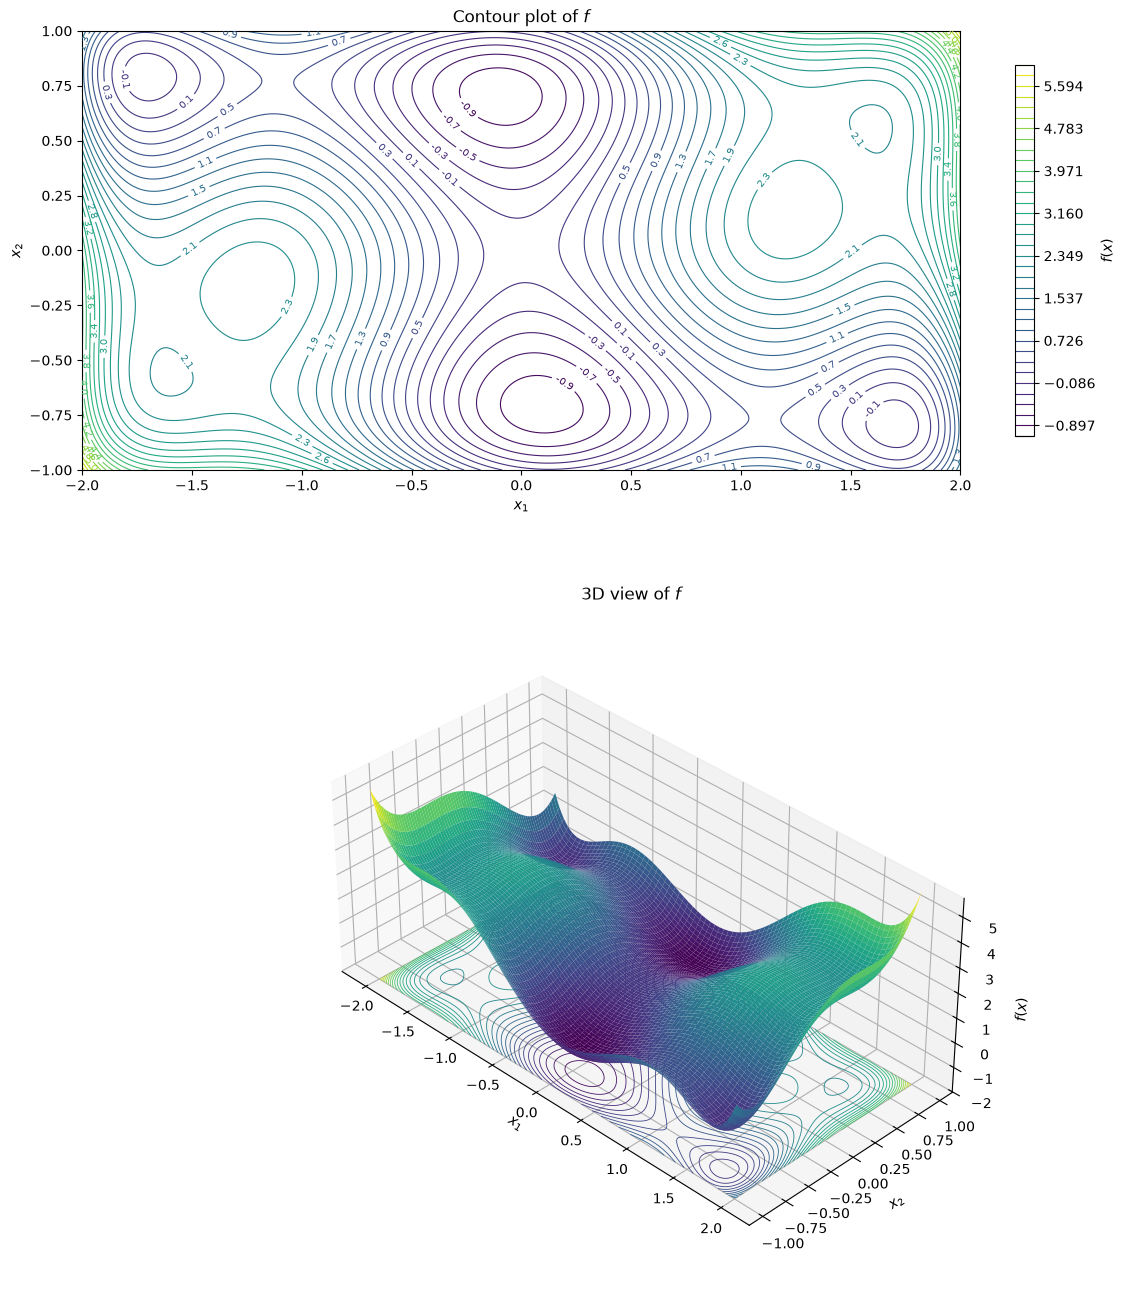

In [51]:
# PLOT MADE WITH THE HELP OF AI

def f_mm(x):
    return x[0]**2 * (4 - 2.1*x[0]**2 + x[0]**4/3) + x[0]*x[1] + x[1]**2 * (-4 + 4*x[1]**2)

def grad_f_mm(x):
    return np.array([8*x[0] - 8.4*x[0]**3 + 2*x[0]**5 + x[1],
                     x[0] - 8*x[1] + 16*x[1]**3])

# Grid in x1 in [-2, 2], x2 in [-1, 1]
X1, X2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 1, 400))
Z_mm = f_mm(np.array([X1, X2]))
levels_mm = np.linspace(-1.1, 6, 36)

def contour_mm(ax, show_minima=True):
    # Contour lines of f, reused by the plots of this section (the minima are defined in 1.2.1)
    cs = ax.contour(X1, X2, Z_mm, levels=levels_mm, cmap="viridis", linewidths=0.8)
    if show_minima:
        ax.plot(minima[:2, 0], minima[:2, 1], "*", color="gold", mec="k", ms=16, label="global minima")
        ax.plot(minima[2:, 0], minima[2:, 1], "*", color="silver", mec="k", ms=12, label="local minima")
    ax.set_xlim(-2, 2); ax.set_ylim(-1, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return cs

fig = plt.figure(figsize=(12, 14))

# Contour plot
ax = fig.add_subplot(2, 1, 1)
cs = contour_mm(ax, show_minima=False)
ax.clabel(cs, fontsize=7, fmt="%.1f")
fig.colorbar(cs, ax=ax, label="$f(x)$", shrink=0.55)
ax.set_title("Contour plot of $f$")

# 3D view
ax3d = fig.add_subplot(2, 1, 2, projection="3d")
ax3d.plot_surface(X1, X2, Z_mm, cmap="viridis", rstride=5, cstride=5, linewidth=0, antialiased=True)
ax3d.contour(X1, X2, Z_mm, levels=levels_mm, cmap="viridis", linewidths=0.6, offset=Z_mm.min() - 1)
ax3d.set_zlim(Z_mm.min() - 1, Z_mm.max())
ax3d.set_xlabel("$x_1$"); ax3d.set_ylabel("$x_2$"); ax3d.set_zlabel("$f(x)$")
ax3d.set_box_aspect((2, 1, 0.8))
ax3d.view_init(elev=35, azim=-45)
ax3d.set_title("3D view of $f$")

plt.tight_layout()
plt.show()

#### 1.2.1 Gradient descent with a constant $\alpha^{k} = 0.1$ from different starting points

                x0 |   x after 100 iterations |     f(x) | ||grad f(x)||
--------------------------------------------------------------------------
 (-1.5000, 0.8000) |        (-1.6221, 0.9095) |   0.0110 |    3.4065e+00
 (1.5000, -0.8000) |        (1.6221, -0.9095) |   0.0110 |    3.4065e+00
  (0.5000, 0.5000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
(-0.5000, -0.5000) |        (0.0898, -0.7127) |  -1.0316 |    1.7902e-15
  (1.0000, 0.9000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
(-1.9000, -0.9000) |        (0.0898, -0.7127) |  -1.0316 |    1.7902e-15
  (1.9000, 0.2000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
 (-1.0000, 0.0000) |        (-0.0898, 0.7127) |  -1.0316 |    1.7902e-15
  (1.4000, 0.3000) |         (1.6071, 0.5687) |   2.1043 |    1.8310e-15


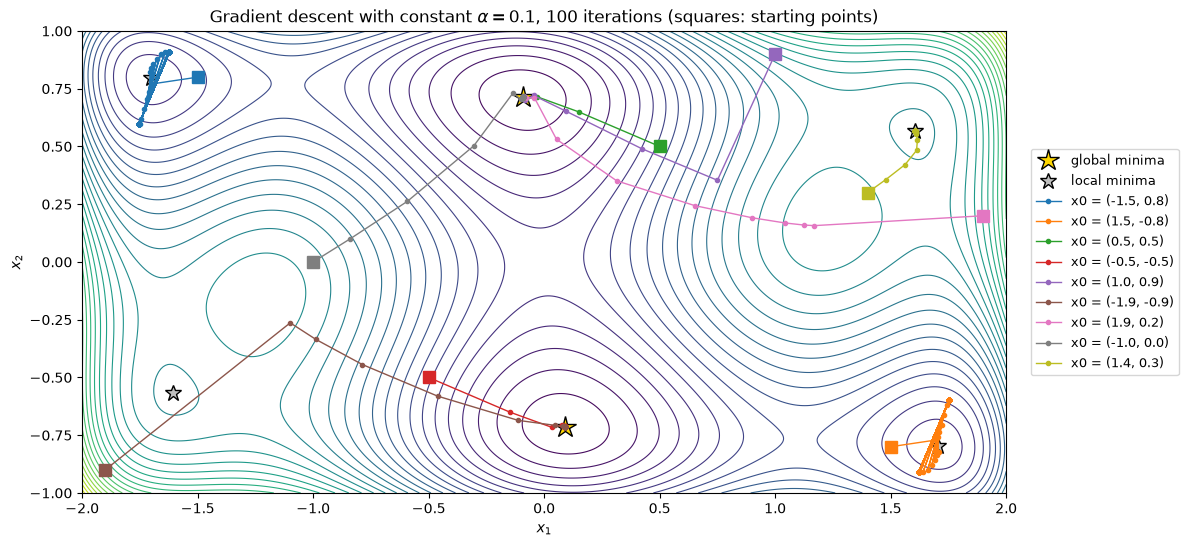

In [52]:
# MADE WITH AI

# Starting points spread over the box, the same ones are used in 1.2.2
starts_mm = np.array([[-1.5,  0.8], [ 1.5, -0.8], [ 0.5,  0.5], [-0.5, -0.5],
                      [ 1.0,  0.9], [-1.9, -0.9], [ 1.9,  0.2], [-1.0,  0.0],
                      [ 1.4,  0.3]])

paths_const = [grad_desc_path(grad_f_mm, x0_mm, alpha=0.1, max_iter=100) for x0_mm in starts_mm]

print(f"{'x0':>18} | {'x after 100 iterations':>24} | {'f(x)':>8} | {'||grad f(x)||':>13}")
print("-" * 74)
for x0_mm, path in zip(starts_mm, paths_const):
    x = path[-1]
    print(f"{f'({x0_mm[0]:.4f}, {x0_mm[1]:.4f})':>18} | {f'({x[0]:.4f}, {x[1]:.4f})':>24} | "
          f"{f_mm(x):>8.4f} | {np.linalg.norm(grad_f_mm(x)):>13.4e}")

fig, ax = plt.subplots(figsize=(12, 6))
contour_mm(ax)
colors = plt.cm.tab10.colors
for i, (x0_mm, path) in enumerate(zip(starts_mm, paths_const)):
    ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
            label=f"x0 = ({x0_mm[0]:.1f}, {x0_mm[1]:.1f})")
    ax.plot(*x0_mm, "s", color=colors[i], ms=9)
ax.set_title(r"Gradient descent with constant $\alpha = 0.1$, 100 iterations (squares: starting points)")
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()


**Conclusions**

- **Most starting points converge to the minimum of their own valley.** 7 of the 9 starting points reach a minimum after 100 iterations (with $\|\nabla f\| \approx 10^{-15}$). Each one ends at the minimum of the valley where it started: for instance $(0.5, 0.5)$ goes to the global minimum $(-0.0898, 0.7127)$ and $(-0.5, -0.5)$ to the other global minimum $(0.0898, -0.7127)$.
- **Gradient descent only finds local minima.** From $(1.4, 0.3)$ the method converges to $(1.6071, 0.5687)$, where $f = 2.1043$, much worse than the global minimum $f = -1.0316$. The gradient only uses local information, so once the iterate is inside a valley it cannot leave it. Which minimum we find depends on $x^{0}$.
- **From $(\pm 1.5, \mp 0.8)$ the method does not converge.** The iterates end up jumping between $(-1.6221, 0.9095)$ and $(-1.7545, 0.5956)$ (and the symmetric points), around the local minimum $(-1.7036, 0.7961)$, with $\|\nabla f\| \approx 3.4$ after 100 iterations. This is the same problem as with $\alpha = 1$ in 1.1.2. Near a minimum $x^{*}$, $f$ behaves like a quadratic with Hessian $H = \nabla^{2} f(x^{*})$ and
$$
    x^{k+1} - x^{*} \approx (I - \alpha H)(x^{k} - x^{*}),
$$
so the method only converges if $|1 - \alpha\lambda| < 1$ for every eigenvalue $\lambda$ of $H$, i.e. $\alpha < 2/\lambda_{\max}$:

| minimum | eigenvalues of $H$ | largest valid $\alpha$ ($2/\lambda_{\max}$) |
|---|---|---|
| $(\pm 0.0898, \mp 0.7127)$ | 7.68, 16.49 | 0.121 |
| $(\pm 1.6071, \pm 0.5687)$ | 7.12, 10.02 | 0.200 |
| $(\pm 1.7036, \mp 0.7961)$ | 18.82, 22.70 | 0.088 |

The valley of $(\pm 1.7036, \mp 0.7961)$ is too steep for $\alpha = 0.1$ ($1 - 0.1 \cdot 22.70 = -1.27$): every step overshoots the minimum. Since $f$ is not quadratic, the iterates do not diverge as in 1.1.2, but they get stuck in a 2-cycle. A constant step that works for one valley may not work for another, which motivates choosing $\alpha^{k}$ at every iteration.

#### 1.2.2 Gradient descent with backtracking

*MADE WITH AI*

At every iteration $k$ we start with $\alpha^{k} = 1$ and halve it until $f(x^{k} - \alpha^{k}\nabla f(x^{k})) < f(x^{k})$. Then we update $x^{k+1} = x^{k} - \alpha^{k}\nabla f(x^{k})$. Instead of a fixed number of iterations, we stop when $\|\nabla f(x^{k})\| < 10^{-5}$. To compare both methods fairly, we also run the constant step $\alpha = 0.1$ with the same stopping criterion, from the same starting points as in 1.2.1.

Stopping criterion: ||grad f(x)|| < 1e-5 (at most 10000 iterations)

                x0 |         constant alpha = 0.1         |                  backtracking                 
                   | iterations |                 final x | iterations | halvings |                final x
----------------------------------------------------------------------------------------------------------
 (-1.5000, 0.8000) |     >10000 |       (-1.6221, 0.9095) |         15 |       59 |      (-1.7036, 0.7961)
 (1.5000, -0.8000) |     >10000 |       (1.6221, -0.9095) |         15 |       59 |      (1.7036, -0.7961)
  (0.5000, 0.5000) |         25 |       (-0.0898, 0.7127) |         10 |       33 |      (-0.0898, 0.7127)
(-0.5000, -0.5000) |         25 |       (0.0898, -0.7127) |         10 |       33 |      (0.0898, -0.7127)
  (1.0000, 0.9000) |         28 |       (-0.0898, 0.7127) |         10 |       34 |      (0.0898, -0.7127)
(-1.9000, -0.9000) |         19 |       (0.0898, -0.7127) |         11 |   

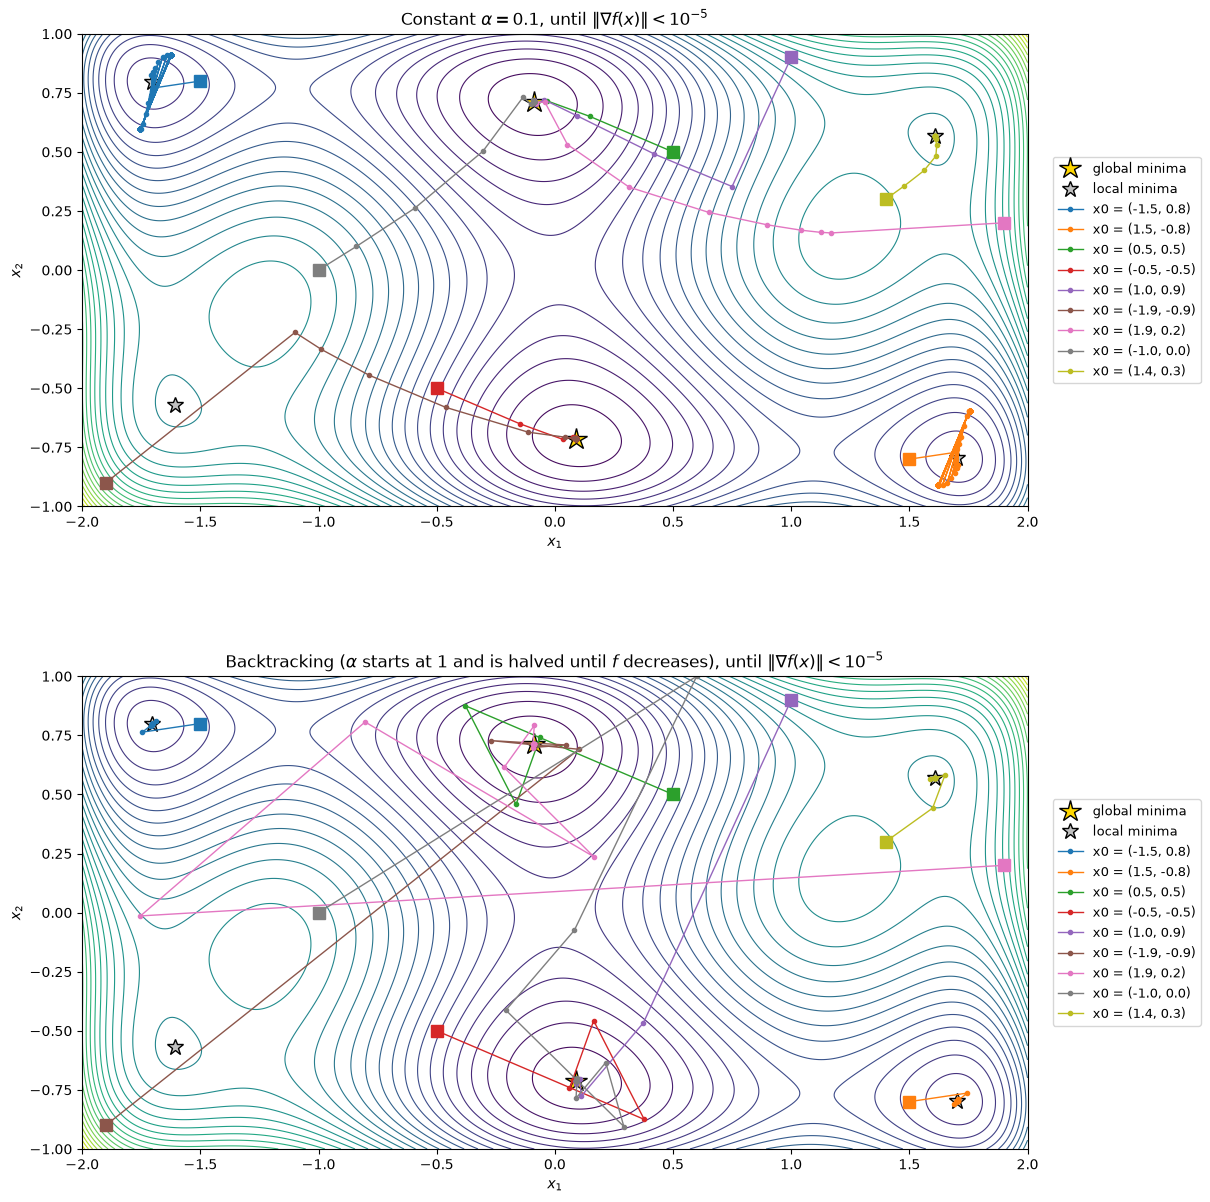

In [53]:
# MADE WITH AI

def grad_desc_backtracking(f, grad_f, x0, tol=1e-5, max_iter=10000, alpha_min=1e-12):
    # Gradient descent where alpha is chosen at every iteration by backtracking:
    # start with alpha = 1 and halve it until f decreases. Stops when ||grad f(x)|| < tol.
    # Returns the path, the alpha used at each iteration and the total number of halvings.
    x = x0
    path = [x]
    alphas = []
    n_halvings = 0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        alpha = 1
        while f(x - alpha * grad) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

def grad_desc_tol(grad_f, x0, alpha, tol=1e-5, max_iter=10000):
    # Constant step gradient descent with the same stopping criterion, to compare iterations
    x = x0
    path = [x]
    for k in range(max_iter):
        if np.linalg.norm(grad_f(x)) < tol:
            break
        x = x - alpha * grad_f(x)
        path.append(x)
    return np.array(path)

results_bt = [grad_desc_backtracking(f_mm, grad_f_mm, x0_mm) for x0_mm in starts_mm]
paths_tol = [grad_desc_tol(grad_f_mm, x0_mm, alpha=0.1) for x0_mm in starts_mm]

print("Stopping criterion: ||grad f(x)|| < 1e-5 (at most 10000 iterations)\n")
print(f"{'x0':>18} | {'constant alpha = 0.1':^36} | {'backtracking':^46}")
print(f"{'':>18} | {'iterations':>10} | {'final x':>23} | {'iterations':>10} | {'halvings':>8} | {'final x':>22}")
print("-" * 106)
for x0_mm, p_tol, (p_bt, alphas, n_halv) in zip(starts_mm, paths_tol, results_bt):
    it_tol = len(p_tol) - 1
    it_tol = f"{it_tol}" if np.linalg.norm(grad_f_mm(p_tol[-1])) < 1e-5 else f">{it_tol}"
    print(f"{f'({x0_mm[0]:.4f}, {x0_mm[1]:.4f})':>18} | {it_tol:>10} | {f'({p_tol[-1][0]:.4f}, {p_tol[-1][1]:.4f})':>23} | "
          f"{len(p_bt) - 1:>10} | {n_halv:>8} | {f'({p_bt[-1][0]:.4f}, {p_bt[-1][1]:.4f})':>22}")

fig, axes = plt.subplots(2, 1, figsize=(12, 13))
for ax, paths, title in zip(axes, [paths_tol, [r[0] for r in results_bt]],
                            [r"Constant $\alpha = 0.1$", r"Backtracking ($\alpha$ starts at 1 and is halved until $f$ decreases)"]):
    contour_mm(ax)
    for i, (x0_mm, path) in enumerate(zip(starts_mm, paths)):
        ax.plot(path[:, 0], path[:, 1], "-o", color=colors[i], ms=3, lw=1,
                label=f"x0 = ({x0_mm[0]:.1f}, {x0_mm[1]:.1f})")
        ax.plot(*x0_mm, "s", color=colors[i], ms=9)
    ax.set_title(title + r", until $\|\nabla f(x)\| < 10^{-5}$")
    ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

*MADE WITH AI*

**Conclusions**

- **Backtracking needs fewer iterations.** It reaches $\|\nabla f\| < 10^{-5}$ from every starting point in only 10 to 15 iterations, far fewer than 100. With the constant step, the starting points that converge need 13 to 29 iterations.
- **Backtracking converges where the constant step got stuck.** From $(\pm 1.5, \mp 0.8)$ the constant step still has not converged after 10000 iterations (it stays in the 2-cycle from 1.2.1), while backtracking reaches the local minimum $(\pm 1.7036, \mp 0.7961)$ in 15 iterations. Since $\alpha^{k}$ is halved until $f$ decreases, the step adapts to the steepness of each valley and never overshoots in a way that increases $f$.
- **Each iteration is more expensive.** Each halving needs one extra evaluation of $f$, and there are 28 to 59 halvings in total per run (about 3 per iteration). So backtracking needs fewer iterations, but every iteration does more work.
- **The minimum found is harder to predict.** Since $\alpha^{k}$ starts at 1, the first steps can be very long, and the condition only asks $f$ to decrease, not to stay in the same valley. From $(1.0, 0.9)$, $(-1.9, -0.9)$ and $(-1.0, 0.0)$ backtracking jumps to the other valley and ends at the opposite global minimum from the constant step. Here this does not matter because both global minima have $f = -1.0316$, but in general the starting valley no longer tells us which minimum we will find.
- **Neither method guarantees the global minimum.** From $(1.4, 0.3)$ both methods stop at the local minimum $(1.6071, 0.5687)$ with $f = 2.1043$, and from $(\pm 1.5, \mp 0.8)$ backtracking stops at a local minimum with $f = -0.2155$. Both are descent methods that stop as soon as the gradient is zero.